In [ ]:
#Bolli Yaswanth Melki , 92400133114 , 5EK2B
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive

In [ ]:
df1 = pd.read_csv('/content/KMeans.csv')
print(df1.head())
X = df1.iloc[:, [1, 2]].values.astype(float)

   Age  Annual Income (k$)  Spending Score (1-100)
0   19                  15                      39
1   21                  15                      81
2   20                  16                       6
3   23                  16                      77
4   31                  17                      40


In [ ]:
# We are directly using KMeans.csv from local runtime paths instead of Google Drive.
print(f"Active dataset shape X: {X.shape}")

Active dataset shape X: (200, 2)


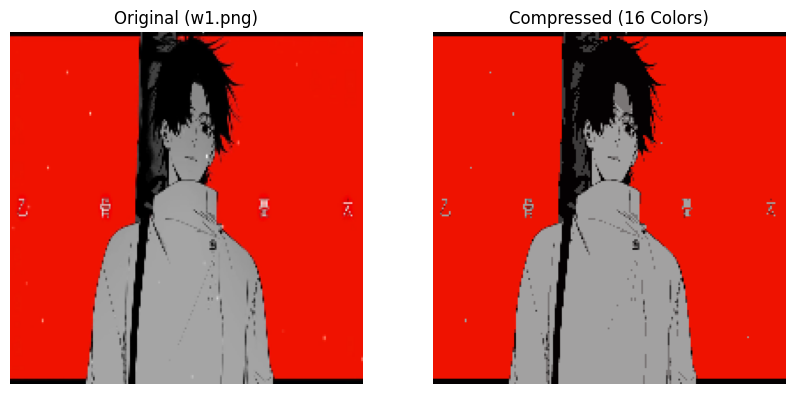

In [ ]:
# Dimensionality Reduction using K-Means for Image Compression
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt
import random

# Configure image path to use 'w1.png'
image_path = '/content/w1.png'

if os.path.exists(image_path):
    im = cv2.imread(image_path)
    im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    im = cv2.resize(im, (200, 200))
else:
    print(f"'{image_path}' not found. Generating a synthetic image placeholder to run the compression code...")
    # Generate a dummy 200x200 RGB image with some patterns
    im = np.zeros((200, 200, 3), dtype=np.uint8)
    for x in range(200):
        for y in range(200):
            im[x, y] = [x % 256, y % 256, (x + y) % 256]

# Normalize and reshape
im_normalized = (im / 255.0).reshape(200 * 200, 3)

# Choose 16 colors for compression (K=16)
K = 16
random_index = random.sample(range(0, len(im_normalized)), K)
centroids = np.array([im_normalized[i] for i in random_index])

# Run K-Means compression
for i in range(15):
    get_centroids = findClosestCentroids(centroids, im_normalized)
    centroids = calc_centroids(get_centroids, im_normalized)

# Reconstruct the compressed image
im_recovered = np.array([centroids[idx] for idx in get_centroids])
im_recovered = im_recovered.reshape(200, 200, 3)

# Display Original vs Compressed
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(im)
ax[0].set_title("Original (w1.png)")
ax[0].axis('off')

ax[1].imshow(im_recovered)
ax[1].set_title(f"Compressed ({K} Colors)")
ax[1].axis('off')

plt.show()